In [1]:
print("Month 3 Data Analysis Portfolio")
print("My Python environment is ready!")

Month 3 Data Analysis Portfolio
My Python environment is ready!


# Week 1: Business Sales Analysis

## Project Overview
The goal of this project is to analyze business sales data to identify sales trends, top-performing products, revenue patterns, and business opportunities.

## Objectives
- Analyze total sales and revenue.
- Identify the best-selling products.
- Examine monthly sales trends.
- Compare product and category performance.
- Create visualizations to communicate findings.
- Provide data-driven business recommendations.

## Tools and Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- SciPy
- Plotly

## Expected Outcome
A complete business sales analysis with data cleaning, exploratory data analysis, visualizations, key insights, and actionable recommendations.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import plotly.express as px

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
sales_data = {
    "Order_ID": [1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010],
    "Product": [
        "Laptop", "Phone", "Headphones", "Laptop", "Tablet",
        "Phone", "Headphones", "Monitor", "Tablet", "Laptop"
    ],
    "Category": [
        "Electronics", "Electronics", "Accessories", "Electronics",
        "Electronics", "Electronics", "Accessories", "Electronics",
        "Electronics", "Electronics"
    ],
    "Quantity": [2, 3, 5, 1, 4, 2, 6, 2, 3, 1],
    "Unit_Price": [50000, 20000, 1500, 50000, 25000, 20000, 1500, 12000, 25000, 50000],
    "Region": [
        "South", "North", "East", "West", "South",
        "North", "East", "West", "South", "North"
    ]
}

df = pd.DataFrame(sales_data)

df["Revenue"] = df["Quantity"] * df["Unit_Price"]

df

,Order_ID,Product,Category,Quantity,Unit_Price,Region,Revenue
0,1001,Laptop,Electronics,2,50000,South,100000
1,1002,Phone,Electronics,3,20000,North,60000
2,1003,Headphones,Accessories,5,1500,East,7500
3,1004,Laptop,Electronics,1,50000,West,50000
4,1005,Tablet,Electronics,4,25000,South,100000
5,1006,Phone,Electronics,2,20000,North,40000
6,1007,Headphones,Accessories,6,1500,East,9000
7,1008,Monitor,Electronics,2,12000,West,24000
8,1009,Tablet,Electronics,3,25000,South,75000
9,1010,Laptop,Electronics,1,50000,North,50000


In [4]:
print("Number of rows and columns:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows and columns: (10, 7)
Number of rows: 10
Number of columns: 7


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Order_ID    10 non-null     int64
 1   Product     10 non-null     str  
 2   Category    10 non-null     str  
 3   Quantity    10 non-null     int64
 4   Unit_Price  10 non-null     int64
 5   Region      10 non-null     str  
 6   Revenue     10 non-null     int64
dtypes: int64(4), str(3)
memory usage: 915.0 bytes


In [7]:
df.describe()

,Order_ID,Quantity,Unit_Price,Revenue
count,10.00000,10.00000,10.000000,10.000000
mean,1005.50000,2.90000,25500.000000,51550.000000
std,3.02765,1.66333,18844.392033,33273.654911
min,1001.00000,1.00000,1500.000000,7500.000000
25%,1003.25000,2.00000,14000.000000,28000.000000
50%,1005.50000,2.50000,22500.000000,50000.000000
75%,1007.75000,3.75000,43750.000000,71250.000000
max,1010.00000,6.00000,50000.000000,100000.000000


In [9]:
df["Revenue"].sum()

np.int64(515500)

In [10]:
total_revenue = df["Revenue"].sum()

print("Total Sales Revenue:", total_revenue)

Total Sales Revenue: 515500


In [11]:
df["Revenue"].mean()

np.float64(51550.0)

In [12]:
average_revenue = df["Revenue"].mean()

print("Average Revenue per Order:", average_revenue)

Average Revenue per Order: 51550.0


In [13]:
df.groupby("Product")["Quantity"].sum()

Product
Headphones    11
Laptop         4
Monitor        2
Phone          5
Tablet         7
Name: Quantity, dtype: int64

In [14]:
product_sales = df.groupby("Product")["Quantity"].sum()

print("Total Quantity Sold by Product:")
print(product_sales)

Total Quantity Sold by Product:
Product
Headphones    11
Laptop         4
Monitor        2
Phone          5
Tablet         7
Name: Quantity, dtype: int64


In [15]:
df.groupby("Product")["Revenue"].sum()

Product
Headphones     16500
Laptop        200000
Monitor        24000
Phone         100000
Tablet        175000
Name: Revenue, dtype: int64

In [16]:
product_revenue = df.groupby("Product")["Revenue"].sum()

print("Total Revenue by Product:")
print(product_revenue)

Total Revenue by Product:
Product
Headphones     16500
Laptop        200000
Monitor        24000
Phone         100000
Tablet        175000
Name: Revenue, dtype: int64


In [17]:
category_revenue = df.groupby("Category")["Revenue"].sum()

print("Revenue by Category:")
print(category_revenue)

Revenue by Category:
Category
Accessories     16500
Electronics    499000
Name: Revenue, dtype: int64


In [18]:
region_revenue = df.groupby("Region")["Revenue"].sum()

print("Revenue by Region:")
print(region_revenue)

Revenue by Region:
Region
East      16500
North    150000
South    275000
West      74000
Name: Revenue, dtype: int64


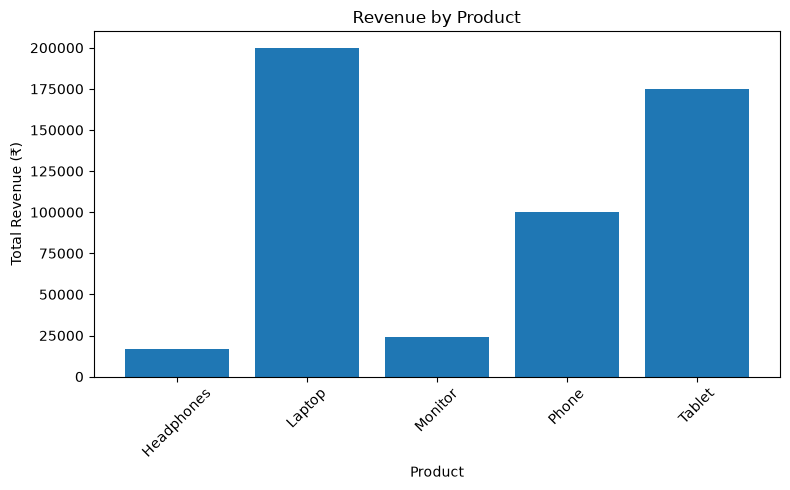

In [19]:
plt.figure(figsize=(8, 5))

plt.bar(product_revenue.index, product_revenue.values)

plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Total Revenue (₹)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

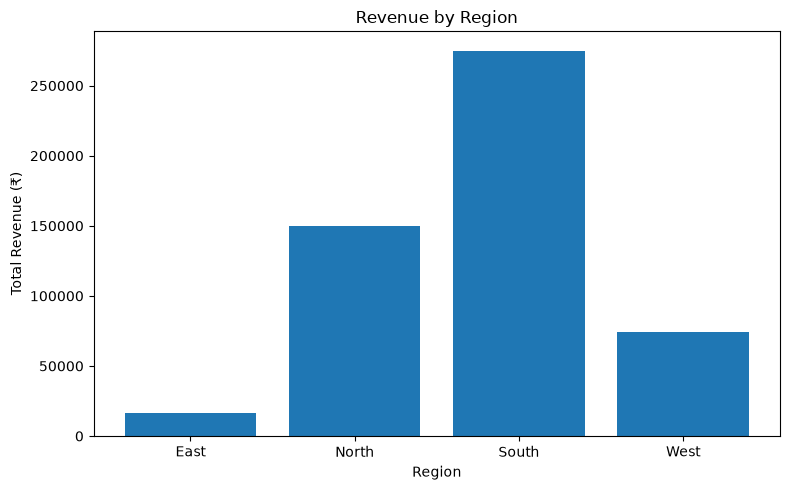

In [20]:
plt.figure(figsize=(8, 5))

plt.bar(region_revenue.index, region_revenue.values)

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue (₹)")

plt.tight_layout()
plt.show()

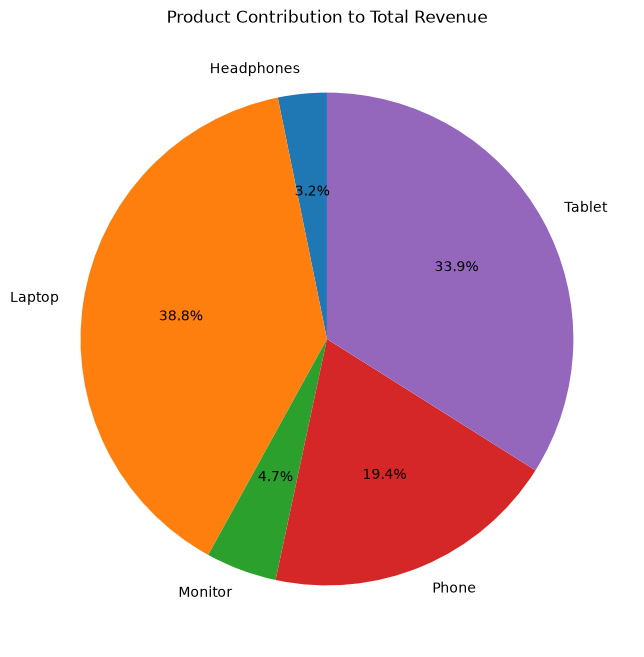

In [21]:
plt.figure(figsize=(8, 8))

plt.pie(
    product_revenue.values,
    labels=product_revenue.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Product Contribution to Total Revenue")
plt.show()

In [22]:
df["Order_Date"] = pd.to_datetime([
    "2026-01-05", "2026-01-12",
    "2026-02-08", "2026-02-15",
    "2026-03-03", "2026-03-17",
    "2026-04-06", "2026-04-19",
    "2026-05-10", "2026-05-22"
])

df

,Order_ID,Product,Category,Quantity,Unit_Price,Region,Revenue,Order_Date
0,1001,Laptop,Electronics,2,50000,South,100000,2026-01-05
1,1002,Phone,Electronics,3,20000,North,60000,2026-01-12
2,1003,Headphones,Accessories,5,1500,East,7500,2026-02-08
3,1004,Laptop,Electronics,1,50000,West,50000,2026-02-15
4,1005,Tablet,Electronics,4,25000,South,100000,2026-03-03
5,1006,Phone,Electronics,2,20000,North,40000,2026-03-17
6,1007,Headphones,Accessories,6,1500,East,9000,2026-04-06
7,1008,Monitor,Electronics,2,12000,West,24000,2026-04-19
8,1009,Tablet,Electronics,3,25000,South,75000,2026-05-10
9,1010,Laptop,Electronics,1,50000,North,50000,2026-05-22


In [23]:
df["Month"] = df["Order_Date"].dt.to_period("M")

monthly_revenue = df.groupby("Month")["Revenue"].sum()

print("Monthly Revenue:")
print(monthly_revenue)

Monthly Revenue:
Month
2026-01    160000
2026-02     57500
2026-03    140000
2026-04     33000
2026-05    125000
Freq: M, Name: Revenue, dtype: int64


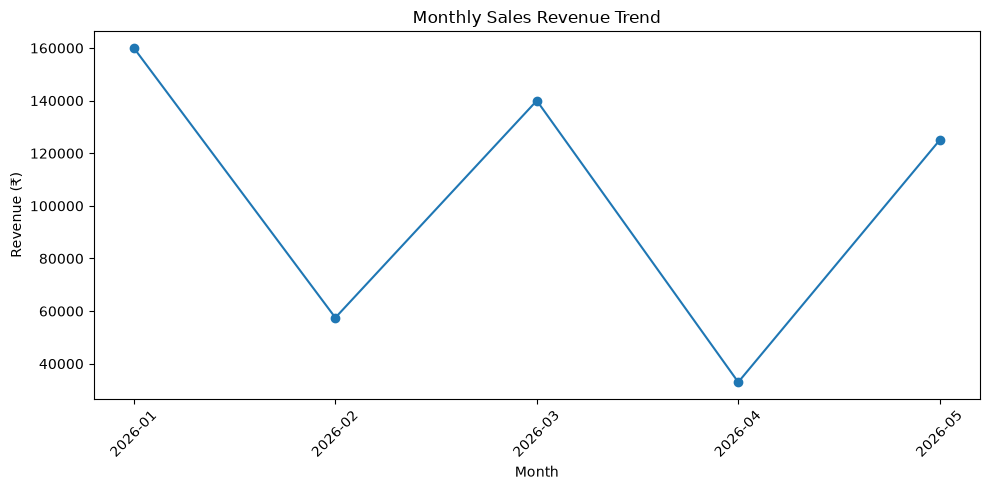

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
# Key Business Sales Statistics

total_revenue = df["Revenue"].sum()
average_revenue = df["Revenue"].mean()
highest_revenue = df["Revenue"].max()
lowest_revenue = df["Revenue"].min()
total_orders = df["Order_ID"].nunique()
total_units_sold = df["Quantity"].sum()

print("BUSINESS SALES SUMMARY")
print("----------------------")
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Average Revenue per Order: ₹{average_revenue:,.2f}")
print(f"Highest Order Revenue: ₹{highest_revenue:,.2f}")
print(f"Lowest Order Revenue: ₹{lowest_revenue:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Total Units Sold: {total_units_sold}")

BUSINESS SALES SUMMARY
----------------------
Total Revenue: ₹515,500.00
Average Revenue per Order: ₹51,550.00
Highest Order Revenue: ₹100,000.00
Lowest Order Revenue: ₹7,500.00
Total Orders: 10
Total Units Sold: 29


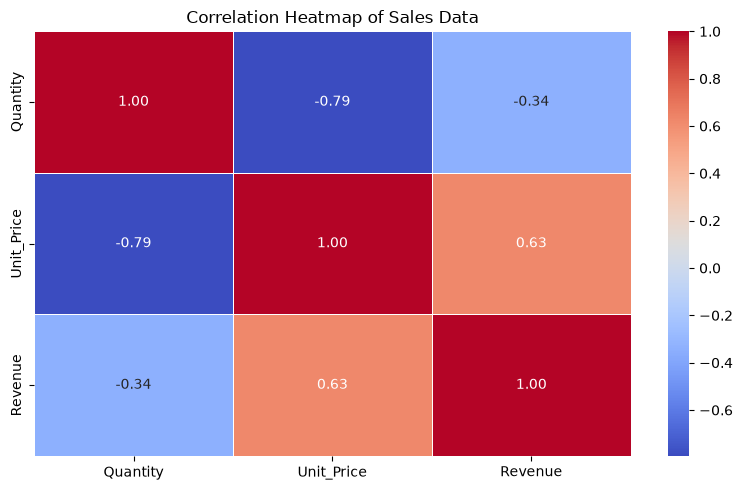

In [26]:
# Select numerical columns
numerical_data = df[["Quantity", "Unit_Price", "Revenue"]]

# Calculate correlation
correlation_matrix = numerical_data.corr()

# Plot heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Sales Data")
plt.tight_layout()
plt.show()

In [27]:
# Rank products by total revenue
product_analysis = df.groupby("Product").agg(
    Total_Quantity=("Quantity", "sum"),
    Total_Revenue=("Revenue", "sum")
)

product_analysis = product_analysis.sort_values(
    by="Total_Revenue",
    ascending=False
)

print("PRODUCT PERFORMANCE RANKING")
display(product_analysis)

PRODUCT PERFORMANCE RANKING


,Total_Quantity,Total_Revenue
Product,,
Laptop,4,200000
Tablet,7,175000
Phone,5,100000
Monitor,2,24000
Headphones,11,16500


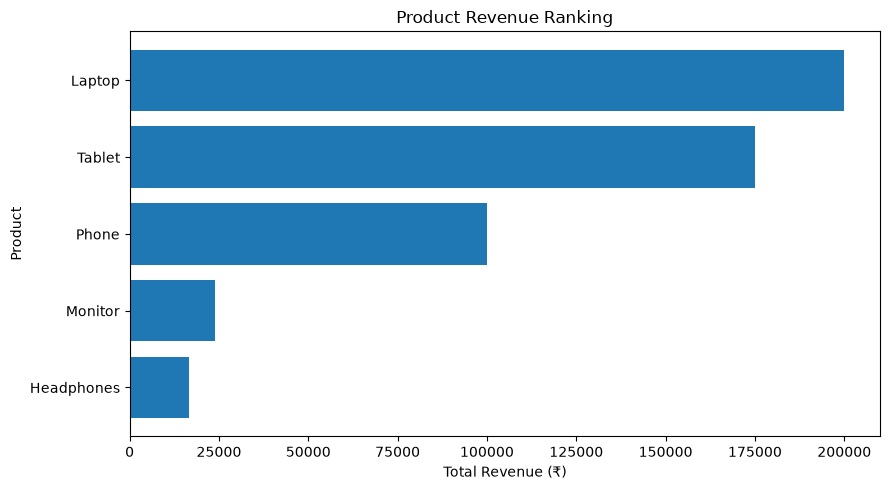

In [28]:
# Sort products by revenue
product_analysis = product_analysis.sort_values(
    by="Total_Revenue",
    ascending=True
)

# Create horizontal bar chart
plt.figure(figsize=(9, 5))

plt.barh(
    product_analysis.index,
    product_analysis["Total_Revenue"]
)

plt.title("Product Revenue Ranking")
plt.xlabel("Total Revenue (₹)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

# Business Sales Analysis Report

## 1. Project Overview
This project analyzes a sample business sales dataset containing 10 orders. The analysis focuses on revenue, product performance, category performance, and regional sales.

## 2. Key Findings

### Overall Sales Performance
- Total revenue: ₹5,15,500
- Total orders: 10
- Total units sold: 29
- Average revenue per order: ₹51,550

### Product Performance
- Laptops generated the highest revenue at ₹2,00,000.
- Tablets generated ₹1,75,000 in revenue.
- Headphones sold the highest number of units, with 11 units sold.
- Monitors generated ₹24,000 in revenue.

### Category Performance
- Electronics generated ₹4,99,000 in revenue.
- Accessories generated ₹16,500 in revenue.
- Electronics contributed the majority of total revenue.

### Regional Performance
- South generated the highest revenue at ₹2,75,000.
- North generated ₹1,50,000.
- West generated ₹74,000.
- East generated the lowest revenue at ₹16,500.

## 3. Business Recommendations

1. **Prioritize high-revenue products:** Review laptop and tablet inventory to help meet customer demand.
2. **Investigate regional performance:** Explore why the South region generates more revenue than the other regions.
3. **Review low-performing products:** Evaluate pricing, promotion, and customer demand for monitors and headphones.
4. **Improve data collection:** Record actual order dates, customer information, discounts, and costs for deeper analysis.
5. **Use larger datasets:** Analyze more orders before making major business decisions.

## 4. Limitations
This analysis uses a small, illustrative dataset containing only 10 orders. The findings cannot be generalized to a real business without validating them against actual sales data.

## 5. Conclusion
The sample analysis shows how Python can be used to summarize sales performance, compare products and regions, and develop data-driven recommendations. A larger real-world dataset would support more reliable conclusions.

In [31]:
# Save the sales dataset as a CSV file
df.to_csv("business_sales_data.csv", index=False)

print("Sales dataset saved successfully!")

Sales dataset saved successfully!
